# Regresión logística: Restaurante(<20)

**Integrante:** [nombre]. **Laboratorio 3 — Ruta Alpes.**

Seguimos la estructura de la [práctica del curso](../MaterialDeClase-ISIS-2611/202620/Prácticas/P7_Regresión logística/P7_RegresionLogistica.ipynb).
La limpieza se documenta en el notebook compartido. Este archivo parte del CSV preparado por el equipo.
Plantilla sin ejecutar: completar las decisiones y los análisis pendientes con evidencia propia.

**Pregunta inicial:** ¿qué características del conductor y del trayecto ayudan a predecir la aceptación de este cupón?


## 1. Importación de librerías


In [30]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)


In [31]:
from sklearn.linear_model import LogisticRegression


## 2. Carga de los datos

Ejecutar desde la raíz de LABORATORIO-3-AM. El CSV debe conservar id_fila, cupon y acepta_cupon en Sí/No.
Puede contener faltantes en predictores: se imputan dentro del pipeline. Los faltantes de la etiqueta no se imputan.


In [32]:
CUPON = 'Restaurante(<20)'
ALGORITMO = 'regresion_logistica'
SEMILLA = 42
N_FOLDS = 5
N_JOBS = -1
RUTA_DATOS = Path('data/procesados/datos_limpios.csv')
RUTA_RESULTADOS = Path('resultados') / 'restaurante_regresion_logistica'
# Completar con las decisiones de la limpieza; mantenerlas entre algoritmos.
# vehiculo, tiempo_cupon_mayor_5min y direccion_opuesta
# ya se eliminaron en el notebook de limpieza compartido.
COLUMNAS_EXCLUIR = []
COLUMNAS_NUMERICAS = ['temperatura']

if not RUTA_DATOS.exists():
    raise FileNotFoundError('Falta data/procesados/datos_limpios.csv. Preparar el CSV y abrir desde la raíz del laboratorio.')
datos = pd.read_csv(RUTA_DATOS)


In [33]:
requeridas = {'id_fila', 'cupon', 'acepta_cupon'}
if not requeridas.issubset(datos.columns):
    raise ValueError(f'Faltan columnas: {requeridas - set(datos.columns)}')
if datos['id_fila'].isna().any() or not datos['id_fila'].is_unique:
    raise ValueError('id_fila debe ser único y no tener faltantes.')
data = datos.loc[datos['cupon'].eq(CUPON)].copy()
data = data.sort_values('id_fila').set_index('id_fila')
if data.empty:
    raise ValueError(f'No se encontraron filas de {CUPON}. Revisar las categorías del CSV.')
if data['acepta_cupon'].isna().any() or not set(data['acepta_cupon']).issubset({'Sí', 'No'}):
    raise ValueError('acepta_cupon debe contener solamente Sí y No, sin faltantes.')
data.head()


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,acepta_cupon
id_fila,,,,,,,,,,,,,,,,,,,,,
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,Sí
5,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí
7,Sin lugar urgente,Hijo(s),Soleado,80,10:00 a.m.,Restaurante(<20),2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí
10,Sin lugar urgente,Hijo(s),Soleado,80,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,Sí
11,Sin lugar urgente,Hijo(s),Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí


## 3. Revisión del subconjunto

La exploración completa y las correcciones pertenecen al notebook de limpieza. Aquí comprobamos qué datos llegan al modelo.


In [34]:
data.shape


(2769, 23)

In [35]:
data.isna().sum()


destino                             0
acompanante                         0
clima                               0
temperatura                         0
hora                                0
cupon                               0
vigencia_cupon                      0
genero                              0
edad                                0
estado_civil                        0
tiene_hijos                         0
educacion                           0
ocupacion                           0
ingreso                             0
frecuencia_bar                     23
frecuencia_cafeteria               47
frecuencia_comida_para_llevar      34
frecuencia_restaurante_menos_20    27
frecuencia_restaurante_20_a_50     43
tiempo_cupon_mayor_15min            0
tiempo_cupon_mayor_25min            0
misma_direccion                     0
acepta_cupon                        0
dtype: int64

In [36]:
data['acepta_cupon'].value_counts()


Sí    1959
No     810
Name: acepta_cupon, dtype: int64

**Por completar:** resumir la distribución de clases, las columnas descartadas y las decisiones de limpieza relevantes para este cupón. No suponer que el balanceo mejorará el resultado antes de medirlo.


## 4. Partición de los datos

Sí se representa con 1 y No con 0. Excluimos cupon, que es constante, y la etiqueta de los predictores. id_fila quedó como índice.
La semilla, la fracción de test y los folds deben ser iguales para los tres modelos del mismo cupón.


In [37]:
X = data.drop(columns=['acepta_cupon', 'cupon', *COLUMNAS_EXCLUIR])
y = data['acepta_cupon'].map({'No': 0, 'Sí': 1}).astype(int)
numericas_features = [c for c in COLUMNAS_NUMERICAS if c in X.columns]
categoricas_features = [c for c in X.columns if c not in numericas_features]

# Conservamos los faltantes como np.nan para SimpleImputer.
# Edad, ingreso y frecuencias son categorías según el diccionario.
for columna in categoricas_features:
    X[columna] = X[columna].astype('string').astype(object)
    X[columna] = X[columna].where(X[columna].notna(), np.nan)
for columna in numericas_features:
    X[columna] = pd.to_numeric(X[columna], errors='raise')
    if not np.isfinite(X[columna].dropna().to_numpy()).all():
        raise ValueError(f'Hay valores no finitos en {columna}. Revisar la limpieza.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)
if y_train.nunique() != 2 or y_train.value_counts().min() < N_FOLDS:
    raise ValueError('Se requieren ambas clases y suficientes ejemplos para cinco folds.')
if numericas_features and X_train[numericas_features].isna().all().any():
    raise ValueError('Hay columnas numéricas completamente vacías en train. Revisar si deben excluirse.')
clase_minoritaria = int(y_train.value_counts().idxmin())
kfold = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Clase minoritaria en train:', {0: 'No', 1: 'Sí'}[clase_minoritaria])


Train: (2215, 21) | Test: (554, 21)
Clase minoritaria en train: No


## 5. Construccion del pipeline

Seguimos el esquema de SimpleImputer y ColumnTransformer de la practica 7. 
La mediana numerica y la moda de cada variable categorica se calculan dentro de cada fold de entrenamiento.


Incluimos StandardScaler porque la regresión usa regularización.


In [38]:
numerica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])


Para regresión usamos drop='first', como en la práctica 7, para interpretar categorías respecto de una referencia. En árbol y bosque conservamos todas las categorías. handle_unknown='ignore' permite recibir categorías nuevas.


In [39]:
categorica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first')),
])


In [40]:
preprocesador = ColumnTransformer(transformers=[
    ('num', numerica_transformer, numericas_features),
    ('cat', categorica_transformer, categoricas_features),
])


In [41]:
pipeline_rl = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', LogisticRegression(max_iter=3000, random_state=SEMILLA)),
])


## 6. Búsqueda de hiperparámetros

Usamos GridSearchCV de forma explícita, como en las prácticas. Se selecciona por F1 macro en CV, dando igual peso a ambas clases. La práctica 7 usa F1 binario; unificamos F1 macro con las prácticas 8–10 para comparar los tres algoritmos. También reportamos el F1 de aceptación.


La grilla sigue la práctica 7: L1/L2, solvers compatibles y valores de C. La rama de compatibilidad permite ejecutar en versiones nuevas de scikit-learn, donde L1/L2 se especifica con l1_ratio.


In [42]:
version_sklearn = tuple(int(v) for v in sklearn.__version__.split('.')[:2])
if version_sklearn < (1, 8):
    param_grid = [
        {'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear'],
         'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]},
        {'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear'],
         'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]},
    ]
else:
    param_grid = [
        {'modelo__l1_ratio': [0], 'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear'],
         'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]},
        {'modelo__l1_ratio': [1], 'modelo__solver': ['liblinear'],
         'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]},
    ]


In [43]:
grid_rl = GridSearchCV(
    estimator=pipeline_rl, param_grid=param_grid,
    cv=kfold, scoring='f1_macro', n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
grid_rl.fit(X_train, y_train)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocesador',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['temperatura']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='most_...
                                                                          'misma_direccion'])])),
                                       ('modelo',
                                        LogisticRegression(max_iter=3000,
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid=[{'modelo__C': [0.1, 0.2, 0.5, 0.8, 1],
                          'modelo__penalty': ['l2'],
                          'modelo__solver': ['newton-cg', 'lbfgs',
                                             'liblinear']},
                         {'modelo__C': [0.1, 0.2, 0.5, 0.8, 1],
                          'modelo__penalty': ['l1'],
                          'modelo__solver': ['liblinear']}],
             return_train_score=True, scoring='f1_macro')

In [44]:
print('Mejores hiperparámetros:', grid_rl.best_params_)
print('F1 macro promedio en CV:', grid_rl.best_score_)
resultados_cv = pd.DataFrame(grid_rl.cv_results_)
columnas_cv = [c for c in resultados_cv.columns if c.startswith('param_')]
columnas_cv += ['mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(resultados_cv[columnas_cv].sort_values('rank_test_score').head(10))
mejor_modelo = grid_rl.best_estimator_
variante_elegida = 'sin_balanceo'


Mejores hiperparámetros: {'modelo__C': 0.2, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}
F1 macro promedio en CV: 0.6671830877984877


,param_modelo__C,param_modelo__penalty,param_modelo__solver,mean_train_score,mean_test_score,std_test_score,rank_test_score
16,0.2,l1,liblinear,0.672929,0.667183,0.025774,1
2,0.1,l2,liblinear,0.681138,0.667176,0.028529,2
1,0.1,l2,lbfgs,0.680824,0.666891,0.023692,3
0,0.1,l2,newton-cg,0.680824,0.666511,0.024359,4
17,0.5,l1,liblinear,0.687746,0.665396,0.025544,5
5,0.2,l2,liblinear,0.687881,0.664912,0.023376,6
3,0.2,l2,newton-cg,0.687770,0.664836,0.024917,7
4,0.2,l2,lbfgs,0.687770,0.664836,0.024917,7
19,1,l1,liblinear,0.691362,0.663388,0.025794,9
18,0.8,l1,liblinear,0.692028,0.662557,0.025553,10


**Por completar:** explicar los hiperparámetros ganadores, comparar train con validación y revisar la dispersión entre folds. Si aparecen advertencias de convergencia, resolverlas antes de reportar el resultado.


## 7. Comparación con SMOTE

Adaptamos el esquema ImbPipeline → SMOTE → modelo de la [práctica 9](../MaterialDeClase-ISIS-2611/202620/Prácticas/P9_KNN_SMOTE/P9_KNN_SMOTE.ipynb). La grilla, los folds y el preprocesamiento son los mismos en ambas variantes. Solo se remuestrean las filas de entrenamiento de cada fold.

**Limitación que se debe discutir:** la práctica usa variables numéricas. Aquí SMOTE recibe también categorías codificadas y puede generar valores one-hot fraccionarios que no corresponden a categorías reales. Este experimento sigue el método visto en clase, pero esa limitación debe constar en la recomendación. SMOTENC o sobremuestreo aleatorio serían alternativas para contrastar si el equipo amplía el estudio.


In [45]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# SMOTE usa cinco vecinos: cada fold necesita al menos seis ejemplos minoritarios.
for indices_train, _ in kfold.split(X_train, y_train):
    if y_train.iloc[indices_train].value_counts().min() <= 5:
        raise ValueError('No hay suficientes ejemplos minoritarios por fold para SMOTE(k_neighbors=5).')


In [46]:
smote_pipeline = ImbPipeline(steps=[
    ('preprocesador', clone(preprocesador)),
    ('smote', SMOTE(random_state=SEMILLA)),
    ('modelo', clone(pipeline_rl.named_steps['modelo'])),
])
smote_grid = GridSearchCV(
    estimator=smote_pipeline, param_grid=param_grid,
    cv=kfold, scoring='f1_macro', n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
smote_grid.fit(X_train, y_train)
print('Mejores parámetros con SMOTE:', smote_grid.best_params_)
print('F1 macro en CV con SMOTE:', smote_grid.best_score_)


Mejores parámetros con SMOTE: {'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}
F1 macro en CV con SMOTE: 0.6778259329132968


In [47]:
comparacion_cv = pd.DataFrame({
    'variante': ['sin_balanceo', 'smote'],
    'f1_macro_cv': [grid_rl.best_score_, smote_grid.best_score_],
})
display(comparacion_cv)
# Decidimos antes de mirar test. En empate conservamos sin balanceo.
if smote_grid.best_score_ > grid_rl.best_score_:
    mejor_modelo = smote_grid.best_estimator_
    variante_elegida = 'smote'
print('Variante elegida por CV:', variante_elegida)


,variante,f1_macro_cv
0,sin_balanceo,0.667183
1,smote,0.677826


Variante elegida por CV: smote


## 8. Evaluación

Como en las prácticas, revisamos reporte de clasificación y matriz de confusión. Test conserva su distribución original y no se usa para ajustar parámetros ni escoger la variante.


              precision    recall  f1-score   support

          No       0.54      0.66      0.59       162
          Sí       0.85      0.77      0.80       392

    accuracy                           0.73       554
   macro avg       0.69      0.71      0.70       554
weighted avg       0.76      0.73      0.74       554

[[107  55]
 [ 92 300]]


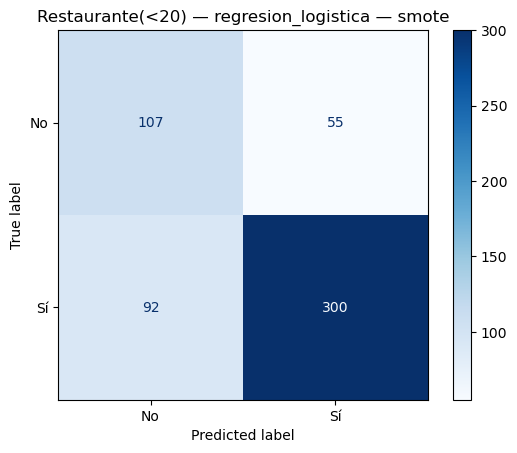

In [48]:
y_pred = mejor_modelo.predict(X_test)
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['No', 'Sí'], zero_division=0))
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['No', 'Sí'], cmap='Blues'
)
plt.title(f'{CUPON} — {ALGORITMO} — {variante_elegida}')
plt.show()


In [49]:
def metricas_modelo(y_true, y_pred):
    return {
        'precision_si': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'recall_si': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_si': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_minoritaria': recall_score(y_true, y_pred, pos_label=clase_minoritaria, zero_division=0),
    }

comparacion_train_test = pd.DataFrame({
    'train': metricas_modelo(y_train, mejor_modelo.predict(X_train)),
    'test': metricas_modelo(y_test, y_pred),
}).T
display(comparacion_train_test.round(3))


,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
train,0.840,0.757,0.796,0.689,0.651
test,0.845,0.765,0.803,0.698,0.660


In [50]:
pred_sin_balanceo = grid_rl.best_estimator_.predict(X_test)
resultados = pd.DataFrame([{
    'cupon': CUPON, 'algoritmo': ALGORITMO, 'variante': 'sin_balanceo',
    'elegida_por_cv': variante_elegida == 'sin_balanceo',
    'f1_macro_cv': grid_rl.best_score_, 'clase_minoritaria': clase_minoritaria,
    **metricas_modelo(y_test, pred_sin_balanceo),
}])


In [51]:
pred_smote = smote_grid.best_estimator_.predict(X_test)
fila_smote = pd.DataFrame([{
    'cupon': CUPON, 'algoritmo': ALGORITMO, 'variante': 'smote',
    'elegida_por_cv': variante_elegida == 'smote',
    'f1_macro_cv': smote_grid.best_score_, 'clase_minoritaria': clase_minoritaria,
    **metricas_modelo(y_test, pred_smote),
}])
resultados = pd.concat([resultados, fila_smote], ignore_index=True)


In [52]:
display(resultados.round(3))


,cupon,algoritmo,variante,elegida_por_cv,f1_macro_cv,clase_minoritaria,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
0,Restaurante(<20),regresion_logistica,sin_balanceo,False,0.667,0,0.796,0.923,0.855,0.692,0.426
1,Restaurante(<20),regresion_logistica,smote,True,0.678,0,0.845,0.765,0.803,0.698,0.660


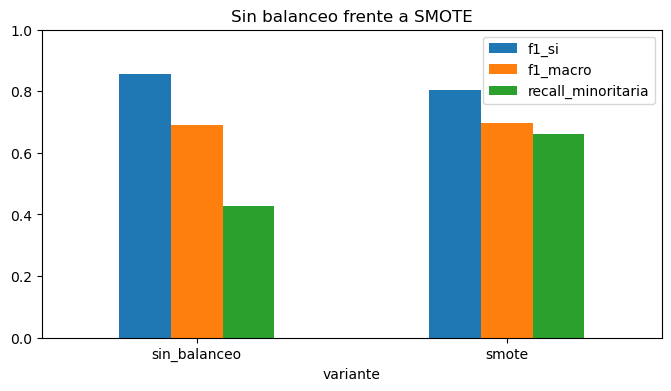

In [53]:
resultados.set_index('variante')[['f1_si', 'f1_macro', 'recall_minoritaria']].plot.bar(
    ylim=(0, 1), figsize=(8, 4), title='Sin balanceo frente a SMOTE'
)
plt.xticks(rotation=0)
plt.show()


**Por completar:** interpretar errores y brecha train–test. En Restaurante, comparar F1 de aceptación, F1 macro y recall minoritario y justificar si conviene SMOTE. En los datos originales la minoritaria de Restaurante es No; verificar después de limpiar. No cambiar la selección en función de test.


## 9. Interpretación del modelo

Seguimos el enfoque de la práctica: coeficientes para regresión, y reducción de impureza y reglas para árboles/bosques. Describen asociaciones del modelo, no relaciones causales.


In [54]:
preprocesador_fit = mejor_modelo.named_steps['preprocesador']
modelo_fit = mejor_modelo.named_steps['modelo']
feature_names = preprocesador_fit.get_feature_names_out()


In [55]:
coeficientes = pd.DataFrame({
    'feature': feature_names, 'coef': modelo_fit.coef_[0],
}).sort_values('coef', ascending=False)
display(coeficientes.head(15))
display(coeficientes.tail(15))

onehot_fit = preprocesador_fit.named_transformers_['cat'].named_steps['onehot']
referencias = pd.DataFrame({
    'variable': categoricas_features,
    'categoria_referencia': [categorias[0] for categorias in onehot_fit.categories_],
})
display(referencias)


,feature,coef
1,cat__destino_Sin lugar urgente,0.690479
10,cat__hora_6:00 p.m.,0.674096
7,cat__clima_Soleado,0.655312
58,cat__ingreso_$50.000 - $62.499,0.327076
77,cat__frecuencia_restaurante_menos_20_más de 8,0.298937
22,cat__estado_civil_Soltero(a),0.252933
13,cat__genero_Masculino,0.161057
53,cat__ocupacion_Ventas y afines,0.144545
23,cat__estado_civil_Unión libre,0.134278
9,cat__hora_2:00 p.m.,0.124127


,feature,coef
83,cat__tiempo_cupon_mayor_15min_Sí,-0.079279
72,cat__frecuencia_comida_para_llevar_menos de 1,-0.097022
5,cat__acompanante_Solo,-0.097808
68,cat__frecuencia_cafeteria_menos de 1,-0.102955
76,cat__frecuencia_restaurante_menos_20_menos de 1,-0.149035
44,cat__ocupacion_Jubilado(a),-0.153996
61,cat__ingreso_$87.500 - $99.999,-0.255235
34,"cat__ocupacion_Artes, Diseño, Entretenimiento,...",-0.291226
70,cat__frecuencia_cafeteria_nunca,-0.303698
28,cat__educacion_Posgrado (Maestría o Doctorado),-0.399546


,variable,categoria_referencia
0,destino,Casa
1,acompanante,Amigo(s)
2,clima,Lluvioso
3,hora,10:00 a.m.
4,vigencia_cupon,1 día
5,genero,Femenino
6,edad,21
7,estado_civil,Casado(a)
8,tiene_hijos,No
9,educacion,Bachillerato completo


Un coeficiente positivo aumenta el logit de aceptación y uno negativo lo reduce, manteniendo lo demás constante. Cada categoría se compara con la referencia omitida; temperatura está estandarizada. La magnitud no equivale automáticamente a importancia global. **Por completar:** interpretar tres asociaciones y su coherencia con el caso.


## 10. Guardar resultados

Persistimos el pipeline, como en la práctica 7, y las métricas para integrar después. Este modelo se ajustó solo en train. El ganador de cada cupón se reajustará con todos sus datos etiquetados al generar el CSV externo.


In [56]:
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
resultados.to_csv(RUTA_RESULTADOS / 'metricas_test.csv', index=False, encoding='utf-8-sig')
resultados_cv.to_csv(RUTA_RESULTADOS / 'cv_sin_balanceo.csv', index=False, encoding='utf-8-sig')
particion = pd.concat([
    pd.DataFrame({'id_fila': X_train.index, 'conjunto': 'train'}),
    pd.DataFrame({'id_fila': X_test.index, 'conjunto': 'test'}),
], ignore_index=True)
particion.to_csv(RUTA_RESULTADOS / 'particion.csv', index=False)
pd.DataFrame({'id_fila': X_test.index, 'real': y_test.to_numpy(), 'prediccion': y_pred}).to_csv(
    RUTA_RESULTADOS / 'predicciones_test_interno.csv', index=False
)
joblib.dump(mejor_modelo, RUTA_RESULTADOS / 'pipeline_evaluado.joblib')


['resultados\\restaurante_regresion_logistica\\pipeline_evaluado.joblib']

In [57]:
pd.DataFrame(smote_grid.cv_results_).to_csv(
    RUTA_RESULTADOS / 'cv_smote.csv', index=False, encoding='utf-8-sig'
)


In [58]:
coeficientes.to_csv(RUTA_RESULTADOS / 'coeficientes.csv', index=False, encoding='utf-8-sig')


## 11. Análisis para el informe conjunto

Completar después de ejecutar y contrastar los seis modelos:

- ¿Qué características se relacionan con la aceptación? ¿Cuáles parecen redundantes?
- ¿Cómo cambia el desempeño entre algoritmos y cupones? ¿Qué explicaría las diferencias?
- ¿Conviene el balanceo en Restaurante considerando F1 y recall minoritario?
- ¿Qué utilidad y limitación tienen las reglas o las importancias?
- ¿Cómo se integraría en la aplicación de conducción?
- ¿Qué limitaciones, fuentes de sesgo e implicaciones tiene usar edad, género, estado civil o ingreso? ¿Qué cambiaría en precios dinámicos?

El documento final debe responder las ocho preguntas del enunciado explícitamente, con evidencia propia.


## 12. Uso de herramientas de IA generativa

**Herramienta y propósito:** Codex (OpenAI), apoyo conceptual y generación/adaptación inicial de código a las prácticas 7–10 del curso. La plantilla se entrega sin resultados de entrenamiento del laboratorio.

**Prompts principales resumidos:**

1. Revisar el lab 3 de 202620, repartir los seis modelos entre dos integrantes y crear un notebook por modelo; dejar la limpieza al estudiante.
2. Revisar las prácticas y adaptar los notebooks a los métodos y la forma de trabajo del curso.

**Evaluación crítica del estudiante — completar al menos dos:** ¿qué fue útil y cómo se verificó?, ¿qué errores o limitaciones se identificaron?, ¿qué decisiones se cambiaron y por qué?, ¿qué conceptos del curso permitieron revisar la propuesta?

**Aportes propios — completar:** decisiones de limpieza, cambios al código, justificaciones, ejecución, interpretación y aprendizajes. Registrar los prompts adicionales que influyan en la entrega.
